# ДЗ 2. Прогнозирование продаж: построение и оценка моделей временных рядов

Курс «Прогнозирование временных рядов и обработка сигналов».

Продолжаю работать с товаром 85099B (JUMBO BAG RED RETROSPOT) и теми рядами, которые получились в ДЗ 1: дневной ряд на торговом календаре, недельный и месячный. Здесь я сравниваю на них несколько моделей на разных горизонтах.

Код устроен так же, как в первом задании. `src/ts_tools.py` это функции из ДЗ 1 (подготовка рядов), а всё новое (модели, проверка, метрики, графики) лежит в `src/forecast_tools.py`. Корень репозитория ноутбук находит сам, выполнять его нужно сверху вниз. Полный запуск занимает несколько минут, основное время уходит на дневной ряд.

In [ ]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ищем корень репозитория (там, где лежит src/forecast_tools.py), откуда бы ни запустили ноутбук
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "forecast_tools.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Не нашла src/forecast_tools.py. Откройте ноутбук из папки репозитория.")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import ts_tools as T          # функции из ДЗ 1
import forecast_tools as F    # модели и оценка качества

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 100
for folder in ("figures", "results"):
    Path(folder).mkdir(exist_ok=True)


def show(name):
    """Сохраняем текущий график в figures/ (для README) и показываем."""
    plt.savefig(f"figures/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## Шаг 1. Данные для прогнозирования

Беру ряды из ДЗ 1. Если в `data/` лежат csv, сохранённые ноутбуком первого задания, читаю их. Если нет, собираю ряды заново из транзакций теми же функциями (датасет при этом скачается с UCI).

In [ ]:
STOCK = "85099B"
NAMES = {"D": "daily", "W": "weekly", "MS": "monthly"}
paths = {k: Path(f"data/sales_{STOCK}_{v}.csv") for k, v in NAMES.items()}

if all(p.exists() for p in paths.values()):
    series = {k: F.load_series(p) for k, p in paths.items()}
    print("Ряды прочитаны из csv (результат ДЗ 1)")
else:
    DATA_FILE = Path("data/Online Retail.xlsx")
    if not DATA_FILE.exists():
        import io, urllib.request, zipfile
        url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
        with urllib.request.urlopen(url) as resp:
            zf = zipfile.ZipFile(io.BytesIO(resp.read()))
        name = [n for n in zf.namelist() if n.lower().endswith(".xlsx")][0]
        DATA_FILE.parent.mkdir(exist_ok=True)
        DATA_FILE.write_bytes(zf.read(name))
    df = T.load_retail(DATA_FILE)
    series = T.build_series(df, STOCK)
    T.save_series(series, STOCK, "data")
    print("Ряды собраны заново из транзакций и сохранены в data/")

Ряды собраны заново из транзакций и сохранены в data/


In [ ]:
for key, s in series.items():
    print(F.CONFIG[key]["title"])
    for name, value in F.check_series(s).items():
        print(f"  {name}: {value}")

Дневной ряд
  n: 304
  начало: 2010-12-01
  конец: 2011-12-08
  индекс возрастает: True
  дубликатов в индексе: 0
  пропусков в значениях: 0
  шаги между датами (дней: сколько раз): {1: 248, 2: 52, 3: 1, 5: 1, 12: 1}
Недельный ряд
  n: 52
  начало: 2010-12-12
  конец: 2011-12-04
  индекс возрастает: True
  дубликатов в индексе: 0
  пропусков в значениях: 0
  шаги между датами (дней: сколько раз): {7: 51}
Месячный ряд
  n: 12
  начало: 2010-12-01
  конец: 2011-11-01
  индекс возрастает: True
  дубликатов в индексе: 0
  пропусков в значениях: 0
  шаги между датами (дней: сколько раз): {28: 1, 30: 3, 31: 7}


Проверяю, что индекс возрастает, в нём нет дубликатов, а в значениях нет пропусков. Всё в порядке. В недельном ряду шаг между датами везде 7 дней, в месячном 28-31 день, это обычные месяцы. В дневном ряду шаг непостоянный: в 248 случаях он равен 1 дню, в 52 случаях 2 дням (это пропущенная суббота), и ещё по одному разу встречаются разрывы в 3, 5 и 12 дней. Самый длинный, 12 дней, это рождественский перерыв из ДЗ 1. Магазин по субботам и в праздники закрыт, такие дни я из ряда убрала, поэтому «шаг вперёд» в дневном ряду означает следующий торговый день, а не следующие сутки.

### Разбиение и схема проверки

Данные делю строго по времени: последние `n_test` наблюдений уходят в тест, всё, что раньше, остаётся для обучения. Размер теста выбрала такой: 90 наблюдений в дневном ряду, 16 в недельном и 4 в месячном, это около трети каждого ряда. Тест в каждом случае не короче максимального горизонта (61 день, 8 недель, 2 месяца), так что оценить можно любой горизонт. Больше отдавать в тест не получается: в месячном ряду всего 12 точек, и на обучении иначе почти ничего не останется.

Прогноз из одной точки дал бы всего по одному значению на горизонт, поэтому использую скользящую проверку с расширяющимся окном. Для каждой даты из теста и каждого горизонта h прогноз делается из точки на h шагов раньше и использует только данные до неё включительно. Так на всех горизонтах оцениваются одни и те же цели из теста, по `n_test` штук, и ошибки на разных горизонтах сравнимы: меняется только то, насколько заранее сделан прогноз. В каждой точке модели переобучаются. Будущего они не видят, потому что функция `forecast_at` отдаёт модели только `series[:origin + 1]`; ниже это проверяется отдельным тестом. Отрицательных продаж не бывает, поэтому прогнозы обрезаю снизу нулём.

In [ ]:
split = pd.DataFrame({F.CONFIG[k]["label"]: F.split_info(len(s), k) for k, s in series.items()}).T
print(split.to_string())
print()
for key, s in series.items():
    cfg = F.CONFIG[key]
    cut = len(s) - cfg["n_test"]
    print(f"{cfg['title']}: обучение до {s.index[cut - 1].date()}, тест с {s.index[cut].date()} по {s.index[-1].date()}")
    assert cfg["n_test"] >= max(cfg["horizons"])

       наблюдений тест макс. горизонт обучение до первого прогноза тест не короче макс. горизонта прогнозов на каждый горизонт
день          304   90             61                          154                           True                           90
неделя         52   16              8                           29                           True                           16
месяц          12    4              2                            7                           True                            4

Дневной ряд: обучение до 2011-08-24, тест с 2011-08-25 по 2011-12-08
Недельный ряд: обучение до 2011-08-14, тест с 2011-08-21 по 2011-12-04
Месячный ряд: обучение до 2011-07-01, тест с 2011-08-01 по 2011-11-01


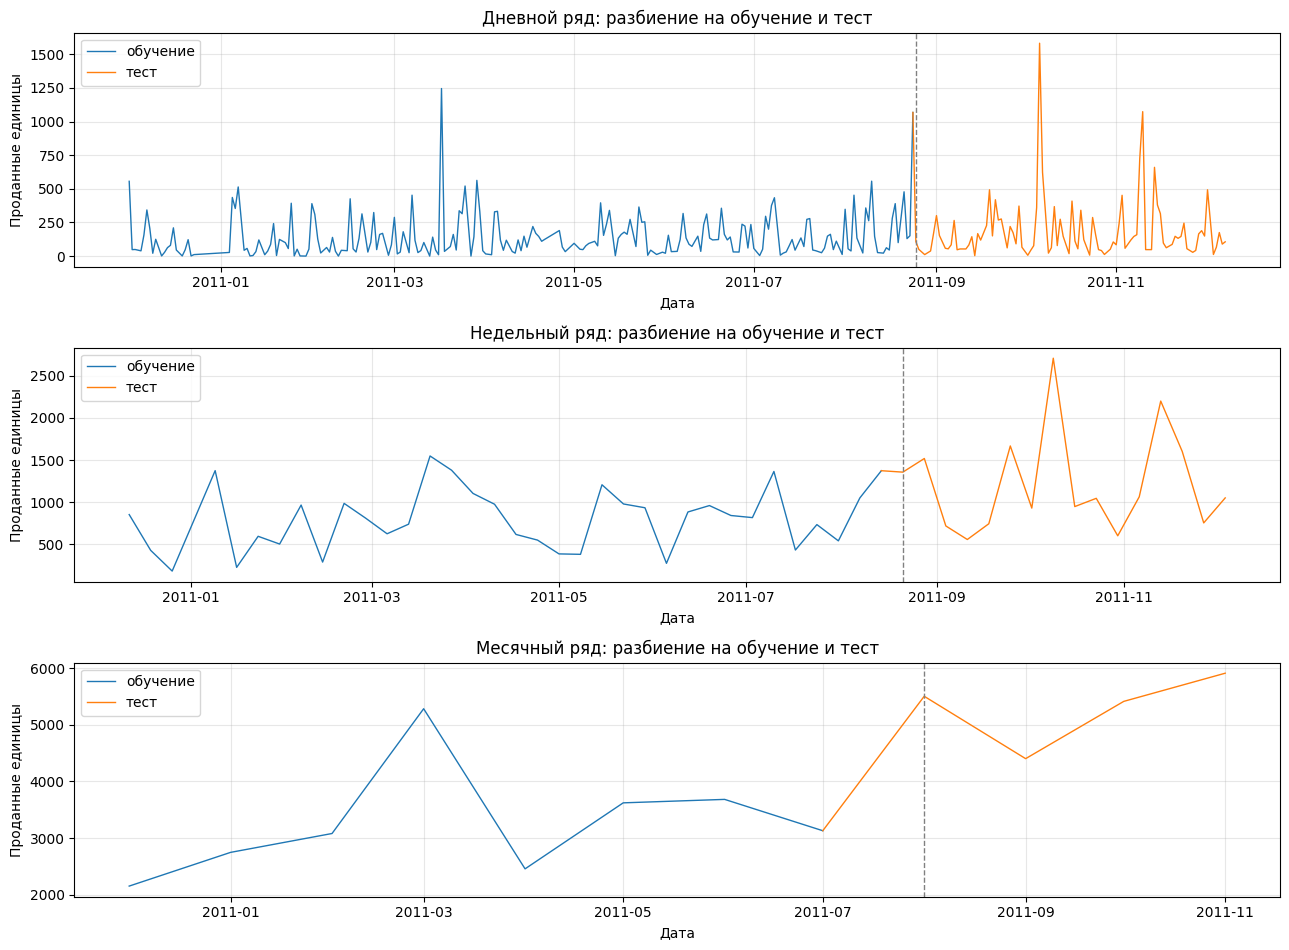

In [ ]:
F.plot_split(series)
show("01_split")

На графиках видно, где проходит граница. Тест приходится на конец ряда, а в ДЗ 1 мы видели, что к осени продажи растут, так что тестовый период в среднем выше обучающего. Это важно помнить при чтении результатов: модели, которые держатся за старый уровень, будут занижать прогноз.

Что нужно по условию, выполнено: в таблице выше видно, что на каждом горизонте у нас по 90, 16 и 4 прогноза, а тест не короче максимального горизонта. В тест попали и крупные всплески дневного ряда, включая самый высокий.

## Шаг 2. Модели

Модели беру из лекции. Всего пять: три основные и две простые, которые нужны как ориентир.

* Naive: прогноз равен последнему наблюдению (наивный подход из лекции).
* MA: среднее последних нескольких наблюдений (окно 6 торговых дней, 4 недели и 2 месяца).
* ETS: экспоненциальное сглаживание. Из SES, Хольта и Хольта-Винтерса выбираю конфигурацию по AICc.
* SARIMA: модель из семейства ARIMA. Порядок подбираю по AICc, а разность беру, если KPSS отвергает стационарность (это продолжение ДЗ 1). В дневном ряду добавляю сезонную AR-часть с периодом 6.
* GBoost: градиентный бустинг (`GradientBoostingRegressor` из sklearn) на признаках из лекции: лаги, скользящие среднее и std, отношение к скользящему среднему и день недели.

Про бустинг подробнее. Использую прямую стратегию: на каждый горизонт своя модель, которая учится предсказывать значение через h шагов. Рекурсивная накапливала бы ошибку, особенно на 61 шаге. Признаки в момент t считаются только по значениям до t включительно. День недели берётся у последнего известного наблюдения, а не у целевой даты: в торговом календаре заранее не знаешь, какие дни впереди окажутся закрытыми. Деревья не умеют экстраполировать, а в ДЗ 1 было видно, что уровень ряда растёт, поэтому модель предсказывает не сам уровень, а отклонение от среднего за последние несколько наблюдений.

Структура ETS и SARIMA выбирается один раз по данным до первого прогноза, то есть без доступа к тесту. Коэффициенты этих моделей и сами деревья переобучаются в каждой точке. Гиперпараметры бустинга (150 деревьев глубины 2, шаг 0,05) я не подбирала, чтобы не усложнять схему: на коротких рядах глубокие деревья быстро переобучаются, поэтому взяла небольшие.

In [ ]:
models, chosen, tables = {}, {}, {}
for key, s in series.items():
    models[key], chosen[key], tables[key] = F.build_models(s, key)
    print(F.CONFIG[key]["title"])
    print("  ETS:", chosen[key]["ETS"])
    print("  SARIMA:", chosen[key]["SARIMA"])

Дневной ряд
  ETS: SES
  SARIMA: (0, 0, 0) x (0, 0, 0, 0)
Недельный ряд
  ETS: SES
  SARIMA: (0, 0, 0) x (0, 0, 0, 0)
Месячный ряд
  ETS: SES
  SARIMA: (0, 0, 0) x (0, 0, 0, 0)


In [ ]:
for key in series:
    print(F.CONFIG[key]["title"])
    print("ETS, AICc (чем меньше, тем лучше):")
    print(tables[key]["ETS"].to_string(index=False))
    print("SARIMA, пять лучших по AICc:")
    print(tables[key]["SARIMA"].head(5).to_string(index=False))
    print()

Дневной ряд
ETS, AICc (чем меньше, тем лучше):
              конфигурация      AICc
                       SES 1,565.365
                      Holt 1,569.144
             Holt (damped) 1,570.879
        Holt-Winters (add) 1,574.252
Holt-Winters (add, damped) 1,579.952
SARIMA, пять лучших по AICc:
 p  d  q  P      AICc
 0  0  0  0 2,002.209
 0  0  0  1 2,003.726
 0  0  1  0 2,004.038
 1  0  0  0 2,004.084
 0  0  2  0 2,005.347

Недельный ряд
ETS, AICc (чем меньше, тем лучше):
 конфигурация    AICc
          SES 346.124
         Holt 351.440
Holt (damped) 354.353
SARIMA, пять лучших по AICc:
 p  d  q  P    AICc
 0  0  0  0 427.217
 0  0  1  0 429.001
 1  0  0  0 429.054
 1  0  1  0 431.654

Месячный ряд
ETS, AICc (чем меньше, тем лучше):
 конфигурация    AICc
          SES 120.255
         Holt     inf
Holt (damped)     inf
SARIMA, пять лучших по AICc:
 p  d  q  P    AICc
 0  0  0  0 123.120
 0  0  1  0 128.456
 1  0  0  0 129.747
 1  0  1  0 143.744



Все три ряда выбрали одно и то же. ETS получилась простейшей, SES (без тренда и сезонности), а SARIMA получилась (0, 0, 0) без сезонной части. KPSS на обучающей части не отвергла стационарность (в таблице у всех d = 0), поэтому разность не бралась, и такая SARIMA с константой это просто среднее по обучающей выборке. Так что «SARIMA» в этом эксперименте по сути прогноз по среднему, а ETS это среднее с адаптивным уровнем.

Дополнительные параметры подбор не оправдали. В дневном ряду Хольт-Винтерс проигрывает SES по AICc (1 574,3 против 1 565,4): слабая недельная сезонность из ДЗ 1 не окупает лишних параметров. Сезонная AR-часть в SARIMA тоже не помогла (2 003,7 против 2 002,2), как и AR- и MA-члены: автокорреляций в ряду мало. В месячном ряду AICc у Хольта бесконечный, на 7 наблюдениях для него просто не хватает данных, так что выбор SES там вынужденный.

Подбор идёт по данным до первого прогноза скользящей проверки, то есть тестовых наблюдений в нём нет. AICc я сравнивала только между моделями с одинаковой разностью (для SARIMA она фиксируется тестом KPSS), потому что при разных порядках разности правдоподобия несопоставимы.

Теперь проверка на утечки. Для каждой модели и частоты беру одну точку, заменяю всё после неё случайным мусором и сравниваю прогнозы: если модель хоть как-то использует будущее, прогноз изменится.

In [ ]:
rows = []
for key, s in series.items():
    cfg = F.CONFIG[key]
    first = len(s) - cfg["n_test"] - max(cfg["horizons"])
    for m in models[key]:
        ok = F.check_no_leakage(m, s, first + 1, cfg["horizons"])
        rows.append({"частота": cfg["label"], "модель": m.name, "прогноз не зависит от будущего": ok})
leak = pd.DataFrame(rows)
print(leak.pivot(index="модель", columns="частота", values="прогноз не зависит от будущего")
      .reindex(F.MODEL_ORDER)[[F.CONFIG[k]["label"] for k in series]].to_string())
assert leak["прогноз не зависит от будущего"].all()

частота  день  неделя  месяц
модель                      
Naive    True    True   True
MA       True    True   True
ETS      True    True   True
SARIMA   True    True   True
GBoost   True    True   True


## Шаг 3. Метрики

Ряды разных частот сильно отличаются по масштабу: в дневном значения порядка сотен штук, в месячном порядка тысяч, и абсолютные ошибки между частотами сравнивать нельзя. Поэтому беру пять метрик, каждая нужна для своего.

* MAE: средняя абсолютная ошибка в штуках. Легко читается и не так чувствительна к крупным заказам.
* RMSE: сильнее наказывает крупные промахи. Нужна, чтобы увидеть, как модели справляются с пиками.
* WAPE: сумма абсолютных ошибок, делённая на сумму фактических значений, в процентах. Не зависит от масштаба и, в отличие от MAPE, не ломается на нулевых днях.
* MASE: MAE, делённая на среднюю ошибку наивного прогноза на один шаг на обучающей части. Тоже безразмерная: значение меньше 1 значит, что модель точнее наивного прогноза.
* ME: средняя ошибка со знаком, факт минус прогноз. Показывает систематическое смещение: положительное значение означает, что модель занижает продажи.

MAPE не использую. В дневном ряду бывают нулевые дни, а при нулевом факте процентная ошибка не определена. Внутри одной частоты и одного горизонта модели можно сравнивать по MAE: на одних и тех же целях MAE, WAPE и MASE отличаются друг от друга только постоянным множителем и расставляют модели в одном порядке, а RMSE может расставить иначе. Между частотами и горизонтами сравниваю WAPE и MASE, потому что они безразмерные.

## Шаг 4. Прогнозы на заданных горизонтах и оценка

Горизонты из условия: в дневном ряду 1, 7, 31 и 61 шаг, в недельном 1, 4 и 8, в месячном 1 и 2. Шаг это один период ряда: торговый день, неделя или месяц. 61 торговый день это чуть больше десяти недель.

In [9]:
forecasts, metrics = [], []
for key, s in series.items():
    cfg = F.CONFIG[key]
    t0 = time.time()
    scale = F.naive_scale(s.to_numpy()[:len(s) - cfg["n_test"]])
    fc = pd.concat([F.rolling_backtest(m, s, key) for m in models[key]], ignore_index=True)
    forecasts.append(fc)
    metrics.append(F.evaluate(fc, scale))
    print(f"{cfg['title']}: готово за {time.time() - t0:.0f} с, "
          f"масштаб для MASE (ошибка наивного прогноза на обучении) = {scale:.2f}")

forecasts = pd.concat(forecasts, ignore_index=True)
metrics = F.sort_models(pd.concat(metrics, ignore_index=True))

Дневной ряд: готово за 107 с, масштаб для MASE (ошибка наивного прогноза на обучении) = 139.65
Недельный ряд: готово за 7 с, масштаб для MASE (ошибка наивного прогноза на обучении) = 376.03
Месячный ряд: готово за 1 с, масштаб для MASE (ошибка наивного прогноза на обучении) = 1105.00


In [10]:
# сколько раз модель не смогла обучиться и вместо неё подставился наивный прогноз
fails = [{"частота": F.CONFIG[k]["label"], "модель": m.name,
          "подстановок наивного прогноза": getattr(m, "failures", getattr(m, "fallbacks", 0))}
         for k in series for m in models[k]]
fails = pd.DataFrame(fails)
bad = fails[fails["подстановок наивного прогноза"] > 0]
print(bad.to_string(index=False) if len(bad) else "Подстановок не было")

Подстановок не было


In [11]:
# все модели прогнозируют одни и те же цели, и ни один прогноз не сделан "из будущего"
counts = forecasts.groupby(["freq", "horizon", "model"], observed=True).size().unstack("model")
print(counts[F.MODEL_ORDER].to_string())

for (k, h), g in forecasts.groupby(["freq", "horizon"]):
    targets = {m: tuple(sorted(x["target"])) for m, x in g.groupby("model")}
    assert len(set(targets.values())) == 1
assert (forecasts["origin"] < forecasts["target"]).all()
print("\nЦели у всех моделей совпадают, прогнозы сделаны только по прошлому")

forecasts.to_csv("results/forecasts.csv", index=False)
metrics.to_csv("results/metrics.csv", index=False)

model         Naive  MA  ETS  SARIMA  GBoost
freq horizon                                
D    1           90  90   90      90      90
     7           90  90   90      90      90
     31          90  90   90      90      90
     61          90  90   90      90      90
MS   1            4   4    4       4       4
     2            4   4    4       4       4
W    1           16  16   16      16      16
     4           16  16   16      16      16
     8           16  16   16      16      16

Цели у всех моделей совпадают, прогнозы сделаны только по прошлому


Выше проверено, что на каждой частоте и горизонте у всех моделей одинаковое число прогнозов, равное `n_test`, и совпадают сами цели, так что сравнение корректное. Прогнозы и фактические значения лежат в `results/forecasts.csv`, метрики в `results/metrics.csv`.

Сводная таблица: одна строка это одна модель на одной частоте и горизонте. `n` число прогнозов, остальные колонки метрики из шага 3 (WAPE в процентах, ME со знаком «факт минус прогноз»).

In [12]:
summary = metrics.copy()
summary["freq"] = summary["freq"].map({k: v["label"] for k, v in F.CONFIG.items()})
summary = summary.rename(columns={"freq": "частота", "horizon": "горизонт", "model": "модель"})
summary.round(2)

,частота,модель,горизонт,n,MAE,RMSE,WAPE,MASE,ME
0,день,Naive,1,90,186.290,297.420,97.560,1.330,-10.690
1,день,MA,1,90,162.350,249.850,85.020,1.160,-13.350
2,день,ETS,1,90,144.510,236.600,75.680,1.030,20.550
3,день,SARIMA,1,90,136.510,235.710,71.490,0.980,38.890
4,день,GBoost,1,90,133.220,236.080,69.760,0.950,25.510
5,день,Naive,7,90,220.870,353.560,115.660,1.580,-16.760
6,день,MA,7,90,182.730,270.750,95.690,1.310,-14.710
7,день,ETS,7,90,144.680,237.800,75.770,1.040,23.740
8,день,SARIMA,7,90,136.350,236.100,71.400,0.980,40.160
9,день,GBoost,7,90,152.900,257.600,80.070,1.090,25.310


In [13]:
for metric in ["WAPE", "MASE"]:
    pv = metrics.pivot_table(index=["freq", "horizon"], columns="model", values=metric,
                             observed=True)[F.MODEL_ORDER]
    print(f"{metric} (строки: частота и горизонт, колонки: модели)")
    print(pv.round(2).to_string())
    print()

WAPE (строки: частота и горизонт, колонки: модели)
model          Naive     MA    ETS  SARIMA  GBoost
freq horizon                                      
D    1        97.560 85.020 75.680  71.490  69.760
     7       115.660 95.690 75.770  71.400  80.070
     31      108.270 82.030 72.230  70.760  90.780
     61       99.970 76.590 70.230  70.230  76.870
W    1        53.550 50.190 39.980  38.720  44.350
     4        54.770 35.370 35.870  39.070  38.530
     8        48.550 44.330 39.800  40.320  49.040
MS   1        23.470 17.170 29.280  33.280  25.710
     2        22.100 23.090 35.550  35.550  28.440

MASE (строки: частота и горизонт, колонки: модели)
model         Naive    MA   ETS  SARIMA  GBoost
freq horizon                                   
D    1        1.330 1.160 1.030   0.980   0.950
     7        1.580 1.310 1.040   0.980   1.090
     31       1.480 1.120 0.990   0.970   1.240
     61       1.370 1.050 0.960   0.960   1.050
W    1        1.730 1.620 1.290   1.250   1.430


В сводных таблицах одна строка это одна частота и один горизонт, по колонкам модели. Сравнивать модели нужно внутри строки, а строки разных частот между собой только по безразмерным WAPE и MASE.

Дневной ряд. Ошибки большие: у лучших моделей WAPE около 70 % (69,76 у GBoost на h=1, 71,40 у SARIMA на h=7, 70,76 на h=31 и 70,23 у ETS и SARIMA на h=61), то есть ошибка сопоставима с самими продажами. Хуже всех Naive (WAPE от 97,56 до 115,66, MASE от 1,33 до 1,58): он повторяет вчерашний всплеск на следующий день, и ошибка появляется дважды, в день всплеска и на следующий (это видно на графике ниже). MA с окном 6 дней размазывает всплеск на неделю, поэтому тоже слабее ETS и SARIMA (MASE 1,05-1,31 против 0,96-1,04). Лучшие модели обгоняют Naive на 28,49-38,27 % по MASE, но между собой три лучшие различаются мало: на h=1 MASE у ETS, SARIMA и GBoost 1,03, 0,98 и 0,95, а MAE 144,51, 136,51 и 133,22. При 90 прогнозах и таком шумном ряде я не стала бы называть победителя уверенно.

Бустинг на дневных данных выигрывает только на h=1 (MASE 0,95). На h=7 и h=31 он заметно слабее ETS и SARIMA (1,09 и 1,24 против 0,98 и 0,97), а его RMSE выше (257,60 и 262,06). По-видимому, на длинных горизонтах признаки по последним значениям почти ничего не говорят о цели, а деревья подстраиваются под шум. Зато RMSE у ETS и SARIMA на всех горизонтах почти одинаковый (от 235,71 до 237,80): его определяют несколько гигантских всплесков, которые не предсказал никто.

Недельный ряд. Лучшие модели дают WAPE 35-40 % (38,72 у SARIMA на h=1, 35,37 у MA на h=4, 39,80 у ETS на h=8), а MASE у всех моделей выше 1 (у лучших 1,25, 1,14 и 1,29). Это не значит, что модели плохи: масштаб MASE это ошибка наивного прогноза на обучении (376,03), а в тесте ряд заметно неровнее, и ошибки всех моделей, включая Naive (MASE 1,57-1,77), выше этой планки. Выигрыш лучших у Naive 27,70, 35,41 и 18,03 %.

Победитель зависит от горизонта, но отрыв небольшой: на h=1 SARIMA (1,25) и ETS (1,29), на h=4 MA (1,14) и ETS (1,16), на h=8 ETS (1,29) и SARIMA (1,30). MA на h=1 заметно хуже (1,62), а на h=4 лучшая, и такая немонотонность на 16 прогнозах скорее шум, чем закономерность. GBoost на h=8 слабее наивного прогноза (1,59 против 1,57).

Месячный ряд. Здесь картина обратная. Лучшие MA на h=1 (MASE 0,82, WAPE 17,17) и Naive на h=2 (MASE 1,06, WAPE 22,10), а ETS и SARIMA хуже всех (1,41 и 1,60 на h=1, 1,71 на h=2). У MA, ETS, SARIMA и GBoost ME совпадает с MAE (например, у ETS на h=1 1 553,40 и там и там), то есть на всех четырёх тестовых месяцах эти модели занижали продажи. ETS и SARIMA усредняют весь прошлый период, где продаж было меньше, а Naive и MA ближе к текущему уровню. Но тест здесь состоит из 4 точек, так что это скорее иллюстрация, чем доказательство.

Между частотами. Безразмерный WAPE падает с укрупнением периода: у лучших моделей около 70 % на дневных данных, 35-40 % на недельных и 17-22 % на месячных. Недельные и месячные суммы предсказать проще, чем дневные, потому что случайные заказы в сумме сглаживаются. MASE между частотами в таком же смысле сравнивать нельзя: он показывает, насколько модель лучше или хуже наивного прогноза своей частоты, а масштабы у частот разные (ошибка наивного прогноза на обучении 139,65 для дней, 376,03 для недель и 1 105,00 для месяцев).

Странное совпадение. На дневном h=61 и месячном h=2 у ETS и SARIMA одинаковы все метрики до последнего знака (например, MAE 134,10 и 1 886,21), а на графиках линия ETS закрыта линией SARIMA. По-видимому, в этих прогнозах ETS тоже выродилась в среднее (параметр сглаживания упёрся в ноль). Напрямую я этого не проверяла.

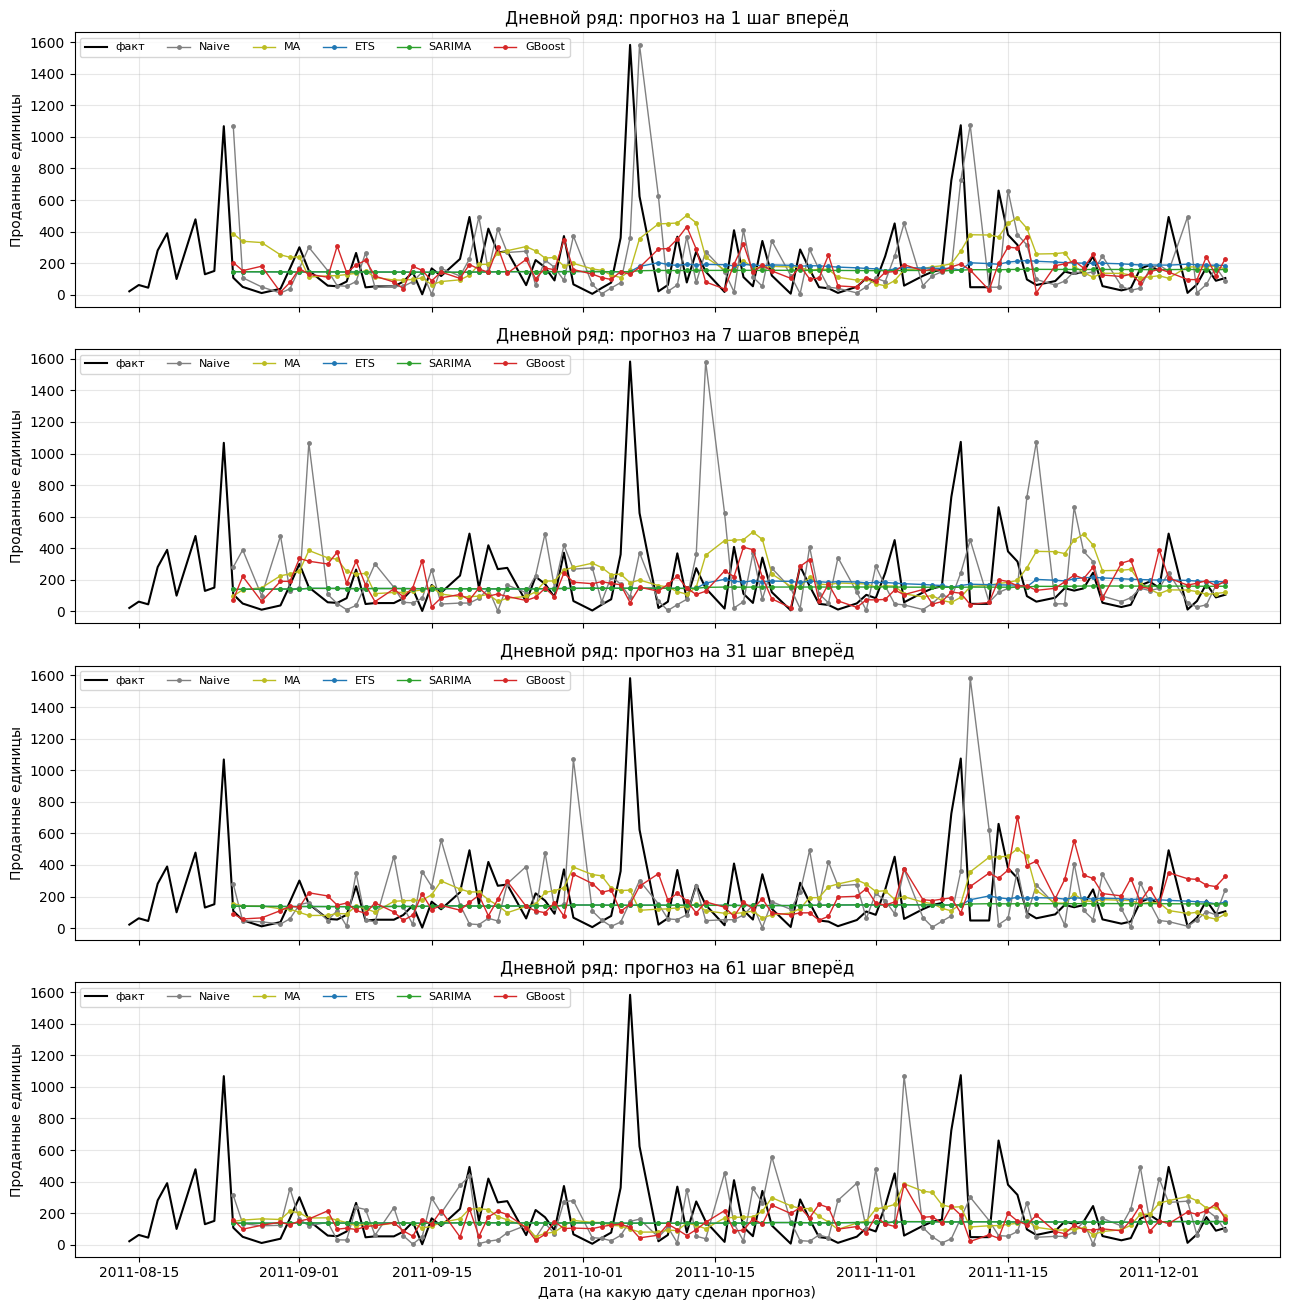

In [14]:
F.plot_forecasts(series["D"], forecasts[forecasts["freq"] == "D"], "D")
show("02_forecasts_daily")

На дневном графике видно, почему метрики такие большие. Самые высокие всплески не предсказывает ни одна модель. ETS и SARIMA это почти горизонтальные линии на низком уровне (SARIMA строго постоянна, это среднее обучающей части, а ETS немного дрейфует). Naive копирует факт со сдвигом, поэтому каждый всплеск появляется в его прогнозе на шаг позже. MA после всплеска остаётся высокой ещё несколько дней. GBoost ближе всех следует за мелкими колебаниями, но пиков тоже не видит. На h=61 линии ETS не видно, она закрыта SARIMA.

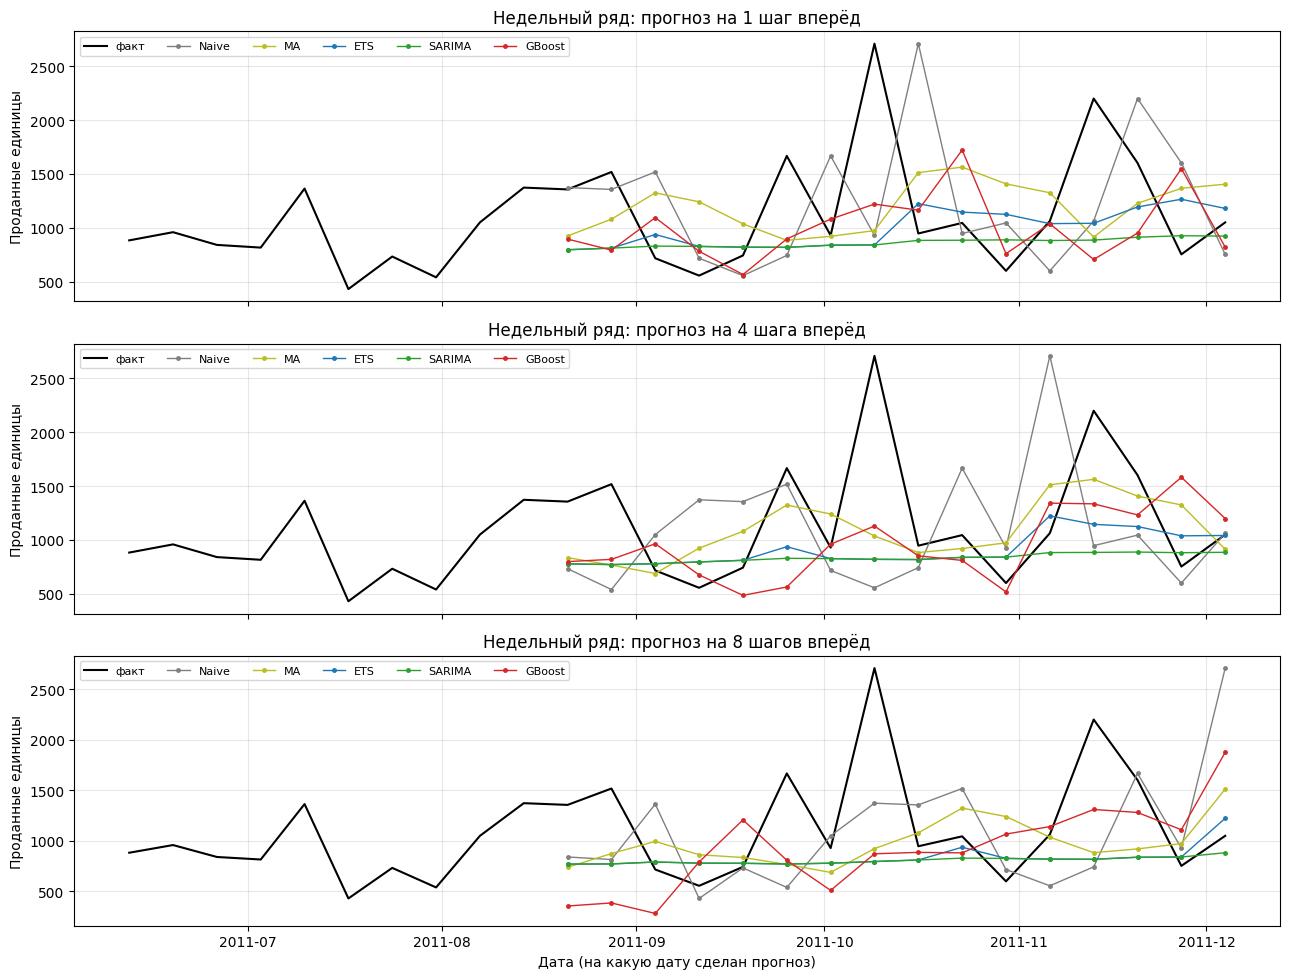

In [15]:
F.plot_forecasts(series["W"], forecasts[forecasts["freq"] == "W"], "W")
show("03_forecasts_weekly")

На недельном графике то же самое, и к тому же хорошо виден рост: осенью продажи выше, чем были летом, а почти горизонтальные прогнозы ETS и SARIMA остаются под фактом. Две высокие недельные вспышки в октябре и ноябре пропущены всеми моделями. У GBoost на h=8 первые прогнозы заметно ниже, чем у остальных моделей: в начале проверки он учится на небольшом числе строк.

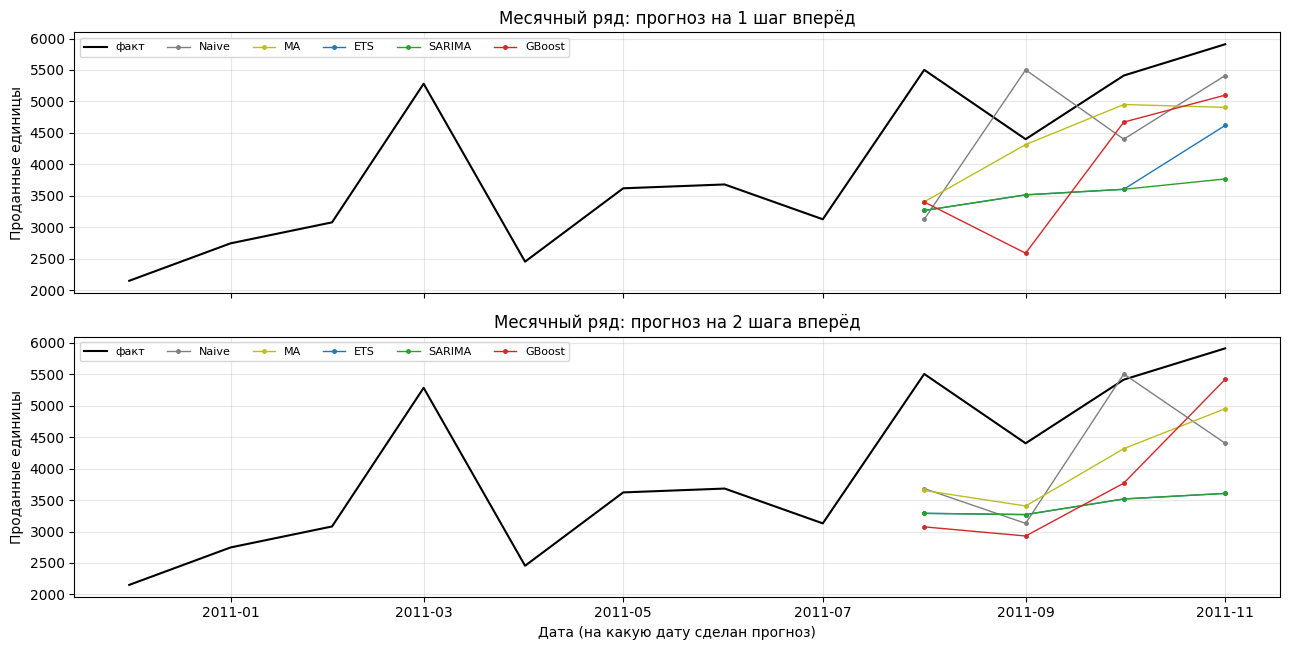

In [16]:
F.plot_forecasts(series["MS"], forecasts[forecasts["freq"] == "MS"], "MS", tail=8)
show("04_forecasts_monthly")

В месячном ряду тест это последние четыре месяца, где продажи в среднем выше, чем в начале и середине ряда. ETS и SARIMA, усредняющие всю историю, на всех четырёх точках остаются ниже факта, а на h=2 линия ETS целиком закрыта линией SARIMA. Naive и MA ближе к факту, потому что быстро подхватывают рост. GBoost сильно колеблется, он обучается на нескольких строках.

Теперь сравнение моделей между горизонтами. Первый график показывает MASE (значения ниже 1 лучше наивного прогноза на шаг вперёд), второй WAPE.

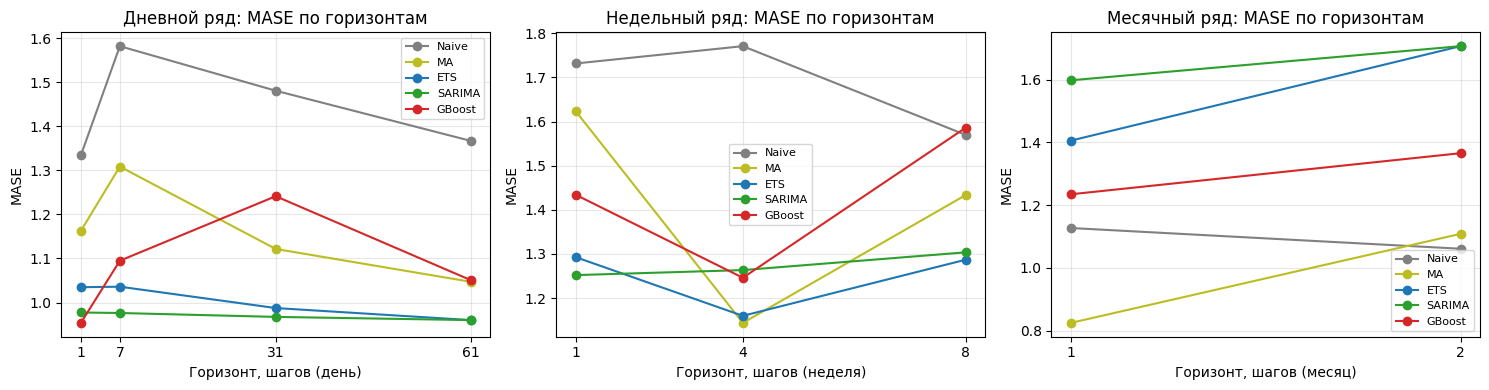

In [17]:
F.plot_metric_by_horizon(metrics, "MASE", "MASE")
show("05_mase_by_horizon")

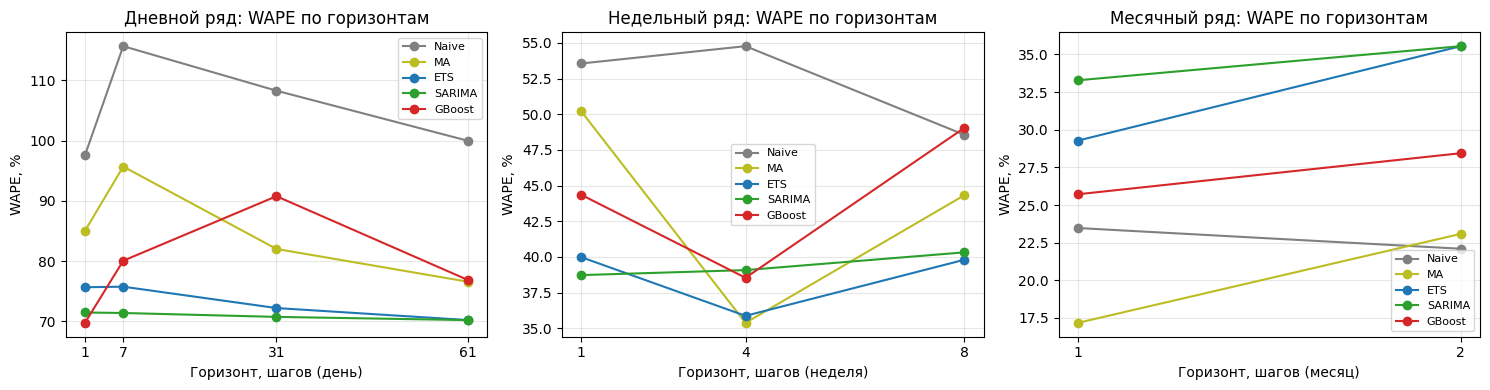

In [18]:
F.plot_metric_by_horizon(metrics, "WAPE", "WAPE, %")
show("06_wape_by_horizon")

С ростом горизонта ошибка почти не растёт, и это неожиданно. В дневном ряду кривые ETS и SARIMA практически плоские (MASE у ETS идёт от 1,03 к 0,96, у SARIMA от 0,98 к 0,96), у Naive и MA нет монотонного роста, и только у GBoost видно, как MASE поднимается с 0,95 до 1,24 на h=31 и опускается до 1,05 на h=61. В недельном ряду у MA и ETS MASE на h=4 даже ниже, чем на h=1 (1,62 и 1,14 у MA, 1,29 и 1,16 у ETS). Исключение месячный ряд: там с h=1 на h=2 ошибка растёт у MA (0,82 и 1,11), ETS (1,41 и 1,71), SARIMA (1,60 и 1,71) и GBoost (1,23 и 1,37), и только Naive улучшается (1,13 и 1,06).

Объяснение простое. ETS и SARIMA дают почти одно и то же значение на любом горизонте, поэтому и ошибка от горизонта не зависит. К тому же сам ряд плохо предсказуем по недавнему прошлому: в ДЗ 1 автокорреляции были слабыми, и прогноз на шаг вперёд оказывается мало лучше прогноза на 61 шаг. Нужно помнить ещё одно: цели на всех горизонтах одни и те же, но прогнозы на длинные горизонты делаются из более ранних точек, то есть по более короткой истории, и для бустинга это важно.

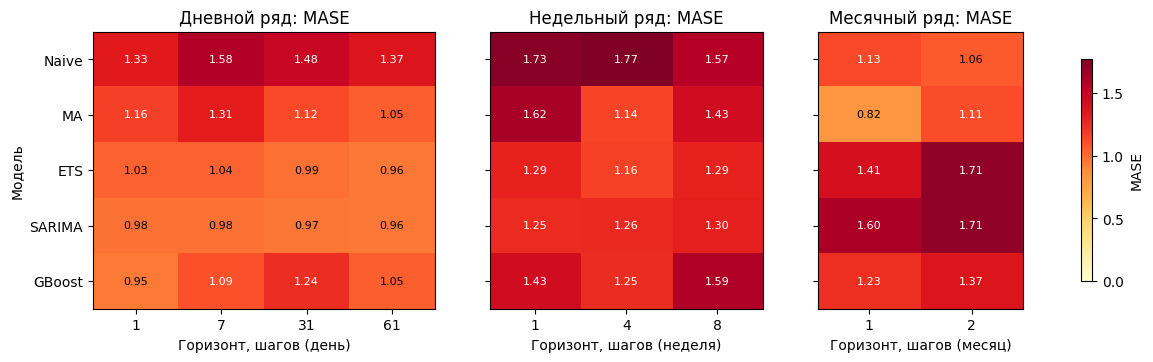

In [19]:
F.plot_heatmap(metrics, "MASE")
show("07_mase_heatmap")

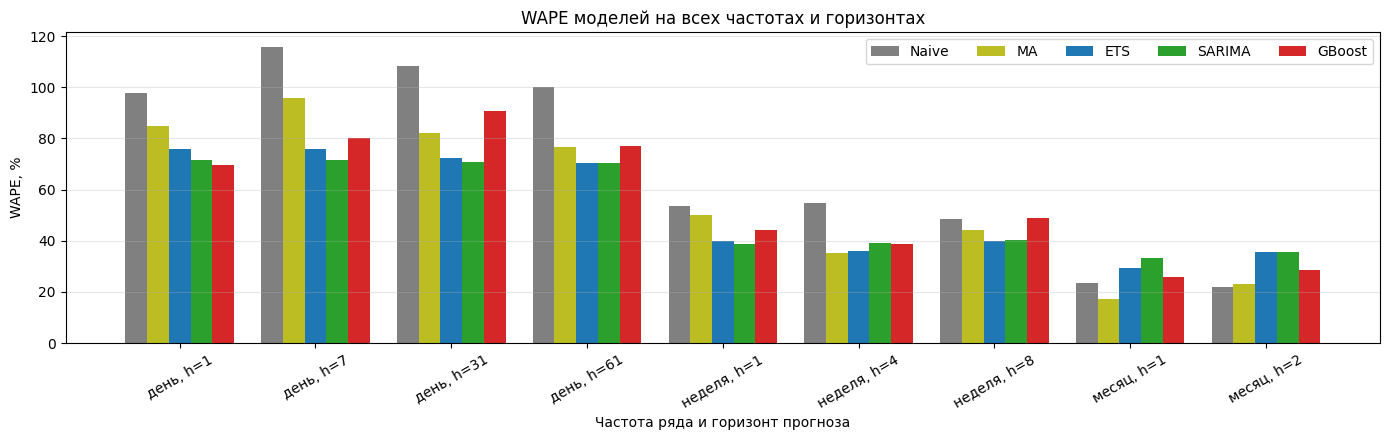

In [20]:
F.plot_wape_overview(metrics)
show("08_wape_overview")

Тепловая карта и столбчатая диаграмма собирают всё вместе. На карте светлее всего клетки с лучшими моделями (дневной ряд: строки ETS и SARIMA, недельный: MA на h=4, месячный: MA на h=1), темнее всего Naive на недельных данных и ETS с SARIMA на месячном h=2. На диаграмме столбцы разных частот можно сравнивать между собой, потому что WAPE безразмерный: видно, как относительная ошибка падает от дневных данных к месячным.

Тепловая карта и столбчатая диаграмма собирают всё в одном месте: на карте светлые клетки это лучшие модели в своей частоте и горизонте, на диаграмме столбцы разных частот можно сравнивать между собой, потому что WAPE безразмерный.

## Шаг 6. Выводы

Сначала цифры, на которые буду опираться: лучшая модель в каждой строке и её выигрыш у наивного прогноза, средний ранг моделей, как растёт ошибка с горизонтом и в какую сторону смещены прогнозы.

In [21]:
best = F.best_models(metrics, "MASE")
best["freq"] = best["freq"].map({k: v["label"] for k, v in F.CONFIG.items()})
print("Лучшая модель по MASE на каждой частоте и горизонте:")
print(best.round(2).to_string(index=False))

best_rmse = F.best_models(metrics, "RMSE")
best_rmse["freq"] = best_rmse["freq"].map({k: v["label"] for k, v in F.CONFIG.items()})
print("\nТо же по RMSE (метрика, чувствительная к пикам):")
print(best_rmse[["freq", "horizon", "лучшая"]].to_string(index=False))

Лучшая модель по MASE на каждой частоте и горизонте:
  freq  horizon лучшая  MASE  MASE Naive  выигрыш у Naive, %
  день        1 GBoost 0.950       1.330              28.490
  день        7 SARIMA 0.980       1.580              38.270
  день       31 SARIMA 0.970       1.480              34.650
  день       61    ETS 0.960       1.370              29.750
неделя        1 SARIMA 1.250       1.730              27.700
неделя        4     MA 1.140       1.770              35.410
неделя        8    ETS 1.290       1.570              18.030
 месяц        1     MA 0.820       1.130              26.840
 месяц        2  Naive 1.060       1.060               0.000

То же по RMSE (метрика, чувствительная к пикам):
  freq  horizon лучшая
  день        1 SARIMA
  день        7 SARIMA
  день       31    ETS
  день       61 SARIMA
неделя        1    ETS
неделя        4     MA
неделя        8     MA
 месяц        1     MA
 месяц        2     MA


In [22]:
metrics["ранг по MASE"] = metrics.groupby(["freq", "horizon"], observed=True)["MASE"].rank()
ranks = metrics.pivot_table(index="freq", columns="model", values="ранг по MASE",
                            aggfunc="mean", observed=True)[F.MODEL_ORDER]
ranks.index = [F.CONFIG[k]["label"] for k in ranks.index]
print("Средний ранг по MASE внутри частоты (1 - лучшая модель, чем меньше, тем лучше):")
print(ranks.round(2).to_string())

Средний ранг по MASE внутри частоты (1 - лучшая модель, чем меньше, тем лучше):
model   Naive    MA   ETS  SARIMA  GBoost
день    5.000 3.500 2.000   1.500   3.000
неделя  4.670 2.670 1.670   2.330   3.670
месяц   1.500 1.500 4.000   5.000   3.000


In [23]:
print("Как меняется MASE с горизонтом (последняя колонка: во сколько раз MASE на самом длинном горизонте")
print("больше, чем на горизонте 1):\n")
for key in series:
    pv = (metrics[metrics["freq"] == key]
          .pivot_table(index="model", columns="horizon", values="MASE", observed=True)
          .reindex(F.MODEL_ORDER))
    pv["макс./мин. горизонт"] = pv.iloc[:, -1] / pv.iloc[:, 0]
    print(F.CONFIG[key]["title"])
    print(pv.round(2).to_string())
    print()

Как меняется MASE с горизонтом (последняя колонка: во сколько раз MASE на самом длинном горизонте
больше, чем на горизонте 1):

Дневной ряд
horizon     1     7    31    61  макс./мин. горизонт
model                                               
Naive   1.330 1.580 1.480 1.370                1.020
MA      1.160 1.310 1.120 1.050                0.900
ETS     1.030 1.040 0.990 0.960                0.930
SARIMA  0.980 0.980 0.970 0.960                0.980
GBoost  0.950 1.090 1.240 1.050                1.100

Недельный ряд
horizon     1     4     8  макс./мин. горизонт
model                                         
Naive   1.730 1.770 1.570                0.910
MA      1.620 1.140 1.430                0.880
ETS     1.290 1.160 1.290                1.000
SARIMA  1.250 1.260 1.300                1.040
GBoost  1.430 1.250 1.590                1.110

Месячный ряд
horizon     1     2  макс./мин. горизонт
model                                   
Naive   1.130 1.060                0.940
MA      

In [24]:
print("Смещение прогнозов, ME = факт - прогноз (больше нуля: модель занижает продажи):\n")
for key in series:
    pv = (metrics[metrics["freq"] == key]
          .pivot_table(index="model", columns="horizon", values="ME", observed=True)
          .reindex(F.MODEL_ORDER))
    print(F.CONFIG[key]["title"])
    print(pv.round(1).to_string())
    print()

Смещение прогнозов, ME = факт - прогноз (больше нуля: модель занижает продажи):

Дневной ряд
horizon      1       7      31     61
model                                
Naive   -10.700 -16.800  6.800 25.600
MA      -13.400 -14.700  6.300 26.000
ETS      20.500  23.700 38.300 50.700
SARIMA   38.900  40.200 45.700 50.700
GBoost   25.500  25.300 -8.600 52.400

Недельный ряд
horizon       1       4       8
model                          
Naive   -20.200 119.300 132.000
MA       22.000 128.600 237.200
ETS     222.200 303.900 381.100
SARIMA  355.600 382.600 409.200
GBoost  213.900 261.500 292.700

Месячный ряд
horizon         1         2
model                      
Naive     695.000 1,127.500
MA        911.200 1,225.000
ETS     1,553.400 1,886.200
SARIMA  1,766.000 1,886.200
GBoost  1,364.400 1,509.100



## Итоговые выводы

Лучшие модели на каждой частоте и горизонте по MASE (в скобках для сравнения MASE наивного прогноза):

| Частота | Горизонт | Лучшая модель | MASE | MASE Naive |
|---|---|---|---|---|
| день | 1 | GBoost | 0,95 | 1,33 |
| день | 7 | SARIMA | 0,98 | 1,58 |
| день | 31 | SARIMA | 0,97 | 1,48 |
| день | 61 | ETS (метрики ETS и SARIMA совпадают) | 0,96 | 1,37 |
| неделя | 1 | SARIMA | 1,25 | 1,73 |
| неделя | 4 | MA | 1,14 | 1,77 |
| неделя | 8 | ETS | 1,29 | 1,57 |
| месяц | 1 | MA | 0,82 | 1,13 |
| месяц | 2 | Naive | 1,06 | 1,06 |

По RMSE, которая чувствительна к пикам, лучшая модель в нескольких строках другая: например, на дневном h=1 это SARIMA (235,71 против 236,08 у GBoost), а на недельном h=8 и месячном h=2 это MA. В строках, где лучшая по RMSE другая, разница в RMSE между двумя моделями небольшая, в пределах нескольких процентов.

Общая картина. Простые модели уровня оказались не хуже сложных. На дневных и недельных данных лидировали ETS и SARIMA, у которых прогноз почти постоянный (SARIMA здесь вырождается в среднее по обучающей части). Средний ранг по MASE у SARIMA 1,5 на дневных данных и 2,33 на недельных, у ETS 2,0 и 1,67. Бустинг выиграл только на дневном h=1 (0,95 против 0,98 у SARIMA), а его средний ранг 3,0 на дневных, 3,67 на недельных и 3,0 на месячных данных. На месячном ряду лучшими были Naive и MA (средний ранг 1,5 у обоих), а ETS и SARIMA оказались последними (4,0 и 5,0). Так происходит потому, что в тесте уровень продаж выше, чем в обучении, и модели, усредняющие всю историю, отстают, а Naive и MA быстро подстраиваются.

Как качество меняется с горизонтом. Заметного роста ошибки с горизонтом нет. В дневном ряду MASE у ETS и SARIMA остаётся около 0,96-1,04 на всех четырёх горизонтах, у GBoost есть подъём до 1,24 на h=31, у Naive и MA нет монотонности. В недельном ряду ошибка колеблется без тренда (например, у MA 1,62, 1,14 и 1,43). Единственный случай роста ошибки это месячный ряд у MA, ETS, SARIMA и GBoost, но там всего 4 тестовых точки. При этом смещение с горизонтом заметно растёт: на недельных данных ME у ETS идёт от 222,18 к 303,92 и 381,14, у SARIMA от 355,60 к 382,58 и 409,17, у MA от 22,00 к 128,64 и 237,25. Чем раньше сделан прогноз, тем сильнее модель занижает растущие продажи. На дневных данных ME у ETS и SARIMA положителен на всех горизонтах (от 20,55 до 50,74), то есть эти модели занижают продажи, у GBoost тоже, кроме h=31 (-8,61), а Naive и MA на коротких горизонтах чуть завышают (ME от -16,76 до -10,69 и от -14,71 до -13,35).

Как качество зависит от частоты. Безразмерная ошибка падает с укрупнением: WAPE у лучших моделей около 70 % на дневных данных, 35-40 % на недельных и 17-22 % на месячных. Для практики это значит, что дневной прогноз по этому товару почти бесполезен (ошибка сопоставима с самими продажами), а недельные и месячные суммы предсказываются заметно лучше.

Ограничения и причины ошибок.

* Крупные оптовые заказы. Одиночные большие заказы (как в ДЗ 1) делают дневной ряд непредсказуемым: ни одна модель не угадывает всплески, и RMSE у ETS и SARIMA почти не зависит ни от модели, ни от горизонта (235,71-237,80).
* Рост уровня. Тест приходится на осень, когда продажи выше, чем в обучении. ETS, SARIMA и GBoost занижают прогноз почти везде (ME положителен во всех клетках, кроме дневного h=31 у GBoost), а на месячных данных все модели, кроме Naive, занижают продажи на всех четырёх тестовых точках. Один год данных не позволяет выучить ни годовую сезонность, ни тренд.
* Вырожденные модели. Подбор по AICc оставил ETS в виде SES, а SARIMA в виде среднего (0, 0, 0), потому что автокорреляций в ряду мало. Из-за этого две «разные» модели ведут себя почти одинаково, а в двух случаях (дневной h=61, месячный h=2) даже совпали по метрикам.
* Мало данных. Метрики считаются по 90, 16 и 4 прогнозам, и различия между близкими моделями (например, 0,95, 0,98 и 1,03 на дневном h=1) могут быть случайными. Значимость различий я не проверяла (например, тестом Диболда-Мариано). На месячном ряду выводы только предварительные: 4 точки в тесте и 7 наблюдений при подборе.
* Бустинг. Его гиперпараметры не подбирались, а на длинных горизонтах и коротких рядах он учится на небольшом числе строк. Не исключено, что при настройке и с дополнительными признаками (календарь праздников, цена, число клиентов) он выглядел бы лучше.
* Схема проверки. Для длинных горизонтов прогнозы делаются из более ранних точек, то есть по более короткой истории, поэтому часть различий между горизонтами объясняется не только дальностью прогноза. Прогнозы обрезаны снизу нулём, а шаг дневного ряда это торговый день.

Что можно сделать дальше: добавить трендовую или сезонную компоненту, которая умеет подхватывать рост (например, ETS с трендом на более длинной истории), прогнозировать недельные суммы вместо дневных значений и сравнить модели с проверкой значимости различий.